# 3.2 — Cutoff simulation & trade-off

**Goal**: sweep continuous `score_klavi_2` cutoffs per segment on the labeled book, build the
approval × default **trade-off curve**, pick an operating point, and persist it as
`references/policy_v1.yaml`. The extrapolation to unlabeled stock is a **flagged scenario**,
never the headline.

**Input**: `data/processed/applications_segmented.parquet` (3.0) + the 3.1 missing-score rule.
**Output**: `references/policy_v1.yaml`.

All measured rates come from `Contratado` — the policy family is parametrized by a single risk
tolerance **τ**: *approve every admission unit whose measured default rate ≤ τ*. Units: per named
segment, the nested sets `score ≥ c` (continuous c) plus its scoreless block.

**`(missing)` is out of the τ-sweep by design**: it has no score and no demographics (3.0/3.1) —
there is nothing to condition a cutoff on. Rather than approve it wholesale or extrapolate a
rate we can't justify, the policy **defers to whatever the client already decided** for that
block: `mode: keep_current` (approve iff `STATUS ∈ {Aprovado, Contratado}`). Since every labeled
row is `Contratado` by construction, this means the `(missing)` segment is a **fixed floor** in
the book, present at every τ — its 11.5% default rate is descriptive context, not a decision
input.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import policy as pol  # noqa: E402  (path set above)
from credit_policy import save_fig, palette       # noqa: E402

palette.apply_style()

FIG_DIR = PROJECT_DIR / "reports" / "figures"  # deck figures land here

app = pd.read_parquet(PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet")
lab = app[app["OVER30M2"].notna()].copy()
SEGS = list(lab["segmento"].cat.categories)
NAMED = [s for s in SEGS if s != "(missing)"]
C_SEG = dict(zip(SEGS, ["#1c5cab", "#2a78d6", "#86b6ef", "#e34948", "#eb6834", "0.5"]))

# nested menu per named segment: cumulative-from-top default rate at each distinct score
menus = {}
for s in NAMED:
    d = (lab[(lab["segmento"] == s) & lab["score_klavi_2"].notna()]
         .sort_values("score_klavi_2", ascending=False))
    m = pd.DataFrame({"score": d["score_klavi_2"].values,
                      "bads": d["OVER30M2"].cumsum().values,
                      "n": np.arange(1, len(d) + 1)})
    m["rate"] = m["bads"] / m["n"]
    menus[s] = m.groupby("score", as_index=False).last().sort_values("score", ascending=False)

blocks = {f"{s} [sem score]": lab[(lab["segmento"] == s) & lab["score_klavi_2"].isna()]
          for s in NAMED}
blocks = {k: (len(d), int(d["OVER30M2"].sum())) for k, d in blocks.items()}

# (missing): fixed floor, never swept by tau — every labeled row there is Contratado
miss_lab = lab[lab["segmento"] == "(missing)"]
MISS_N, MISS_B = len(miss_lab), int(miss_lab["OVER30M2"].sum())
print({k: f"{b/n:.1%} (n={n:,})" for k, (n, b) in blocks.items()})
print(f"(missing) floor: {MISS_B/MISS_N:.1%} (n={MISS_N:,}, descriptive only)")

{'A/B/C · Desconhecido [sem score]': '6.8% (n=455)', 'A/B/C · Autônomo [sem score]': '7.9% (n=369)', 'A/B/C · Formal [sem score]': '8.2% (n=195)', 'D/E · Desconhecido [sem score]': '15.9% (n=246)', 'D/E · Autônomo/Formal [sem score]': '14.3% (n=77)'}
(missing) floor: 11.5% (n=11,830, descriptive only)


In [2]:
menus['A/B/C · Desconhecido']

,score,bads,n,rate
293,658.0,0.0,1,0.000000
292,654.0,0.0,2,0.000000
291,653.0,0.0,5,0.000000
290,652.0,0.0,6,0.000000
289,651.0,0.0,7,0.000000
...,...,...,...,...
4,354.0,304.0,3858,0.078797
3,351.0,304.0,3859,0.078777
2,350.0,305.0,3860,0.079016
1,349.0,305.0,3862,0.078975


## 1. The menu — per-segment cutoff sweep

For each named segment: approve `score ≥ c` and read the default rate of the approved set. The
five curves are the raw material the policy chooses from — the per-`classe_social` appetite
lever is visible as the vertical gap between the A/B/C and D/E families.

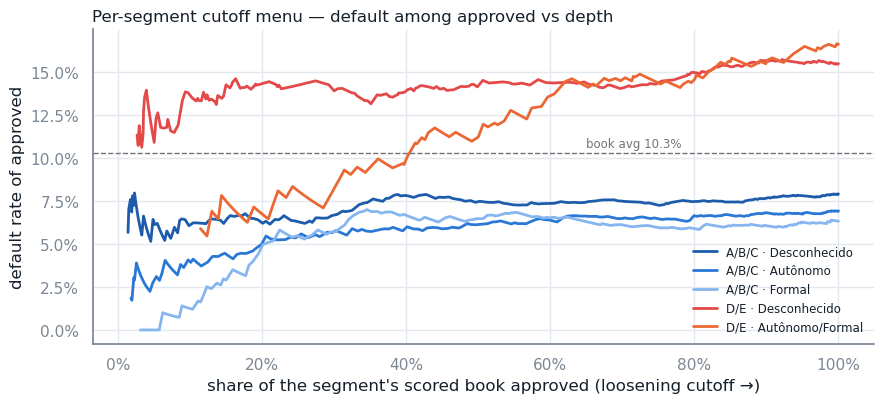

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for s in NAMED:
    m = menus[s][menus[s]["n"] >= 50]                 # unstable head (n < 50) masked
    ax.plot(m["n"] / m["n"].iloc[-1], m["rate"], color=C_SEG[s], lw=2, label=s)
ax.axhline(lab["OVER30M2"].mean(), color="0.45", ls="--", lw=1)
ax.text(0.65, lab["OVER30M2"].mean() + 0.003, f"book avg {lab['OVER30M2'].mean():.1%}",
        color="0.45", fontsize=8.5)
ax.set_xlabel("share of the segment's scored book approved (loosening cutoff →)")
ax.set_ylabel("default rate of approved")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Per-segment cutoff menu — default among approved vs depth", loc="left")
ax.legend(fontsize=8.5, frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

## 2. The policy frontier — sweep the risk tolerance τ

Each τ induces one policy for the **named segments** (a cutoff per segment); the `(missing)`
floor rides along unchanged at every point. The curve shows the whole family on the book: share
kept × default of the kept.

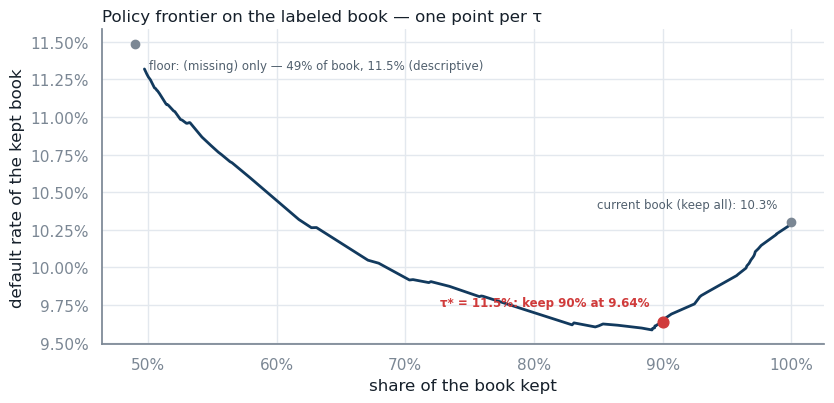

In [4]:
def policy_at(tau):
    """τ → (kept_n, kept_bads, {segment: score_min or inf}, {block: bool}) over NAMED + floor."""
    kept_n, kept_b = MISS_N, MISS_B                       # (missing) floor: always in
    cuts, keeps = {}, {}
    for s in NAMED:
        ok = menus[s][menus[s]["rate"] <= tau]
        cuts[s] = ok["score"].iloc[-1] if len(ok) else np.inf
        if len(ok):
            kept_n += int(ok["n"].iloc[-1]); kept_b += int(ok["bads"].iloc[-1])
    for k, (n, b) in blocks.items():
        keeps[k] = b / n <= tau
        if keeps[k]:
            kept_n += n; kept_b += b
    return kept_n, kept_b, cuts, keeps

taus = np.arange(0.0, 0.1701, 0.001)
front = pd.DataFrame([(t, *policy_at(t)[:2]) for t in taus], columns=["tau", "n", "bads"])
front["kept"] = front["n"] / len(lab)
front["default"] = front["bads"] / front["n"]

TAU_STAR = 0.115
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(front["kept"], front["default"], color=palette.BRAND, lw=2)
ax.scatter([MISS_N / len(lab)], [MISS_B / MISS_N], color=palette.MUTED, zorder=3)
ax.annotate(f"floor: (missing) only — {MISS_N/len(lab):.0%} of book, {MISS_B/MISS_N:.1%} (descriptive)",
            (MISS_N / len(lab), MISS_B / MISS_N), xytext=(10, -18), textcoords="offset points",
            fontsize=8.5, color=palette.INK_2)
ax.scatter([1.0], [lab["OVER30M2"].mean()], color=palette.MUTED, zorder=3)
ax.annotate("current book (keep all): 10.3%", (1.0, lab["OVER30M2"].mean()),
            xytext=(-10, 10), textcoords="offset points", ha="right", fontsize=8.5, color=palette.INK_2)
n_, b_, _, _ = policy_at(TAU_STAR)
ax.scatter([n_ / len(lab)], [b_ / n_], color=palette.RISK_HIGH, zorder=4, s=60)
ax.annotate(f"τ* = 11.5%: keep {n_/len(lab):.0%} at {b_/n_:.2%}", (n_ / len(lab), b_ / n_),
            xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=8.5,
            color=palette.RISK_HIGH, fontweight="bold")
ax.set_xlabel("share of the book kept")
ax.set_ylabel("default rate of the kept book")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Policy frontier on the labeled book — one point per τ", loc="left")
sns.despine()
plt.tight_layout()
save_fig(fig, "fig_tradeoff_frontier.png", FIG_DIR)
plt.show()

**Key takeaway**: no cliff — the `(missing)` floor (49% of the book, 11.5%) sits at every τ.
The curve **dips before it rises**: at very tight τ, only tiny, very-safe named-segment slivers
qualify, diluting the floor's 11.5% down to ~9.6%; as τ loosens, larger and riskier named volume
(including D/E) enters and pulls the blend back up toward the unconditional 10.3%. τ* = 11.5%
sits near the bottom of that dip — 90% of the book at 9.64%, the best default achievable without
discarding evidence-free judgment calls on `(missing)`.

## 3. Operating point → `references/policy_v1.yaml`

τ* = 11.5% for the named segments (conservative: prunes only units measurably worse than the
book average). `(missing)` gets `mode: keep_current` — the policy makes **no new decision**
there. Resulting rules: no score gate in A/B/C, real cutoffs in D/E, scoreless D/E denied,
`(missing)` deferred.

In [5]:
_, _, cuts, keeps = policy_at(TAU_STAR)
policy = {
    "tau": TAU_STAR,
    "segments": {s: {"score_min": None if cuts[s] == menus[s]["score"].min() else float(cuts[s]),
                     "scoreless": "approve" if keeps.get(f"{s} [sem score]") else "deny"}
                 for s in NAMED}
    | {"(missing)": {"mode": "keep_current"}},
}
pol.save_policy(policy, PROJECT_DIR / "references" / "policy_v1.yaml")

kept = pol.approve(lab, policy)
print(f"book: kept {kept.mean():.1%} at {lab.loc[kept, 'OVER30M2'].mean():.2%} "
      f"(removed {1 - kept.mean():.1%}, defaulting at {lab.loc[~kept, 'OVER30M2'].mean():.2%})")
pd.DataFrame(policy["segments"]).T

book: kept 90.0% at 9.64% (removed 10.0%, defaulting at 16.33%)


,score_min,scoreless,mode
A/B/C · Desconhecido,NaN,approve,NaN
A/B/C · Autônomo,NaN,approve,NaN
A/B/C · Formal,NaN,approve,NaN
D/E · Desconhecido,595.0,deny,NaN
D/E · Autônomo/Formal,518.0,deny,NaN
(missing),NaN,NaN,keep_current


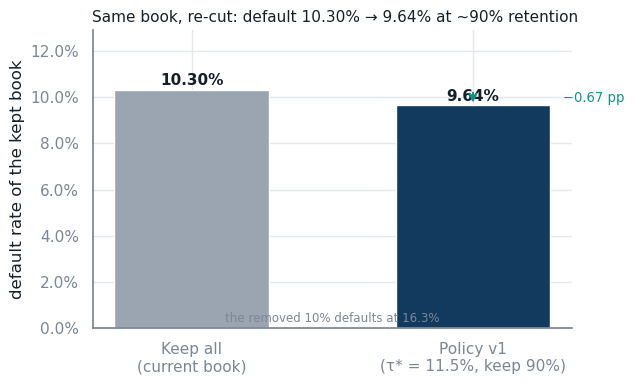

In [6]:
# Deck figure (slide 12) — impact on ONE book scored two ways: keep-all vs policy v1.
# Same 24,148 Contratado rows; the gain is measured on observed performance, not two populations.
keep_all_default = lab["OVER30M2"].mean()
policy_default = lab.loc[kept, "OVER30M2"].mean()
removed_default = lab.loc[~kept, "OVER30M2"].mean()
retention = kept.mean()

fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ["Keep all\n(current book)", f"Policy v1\n(τ* = 11.5%, keep {retention:.0%})"]
vals = [keep_all_default, policy_default]
bars = ax.bar(labels, vals, color=[palette.NEUTRAL, palette.BRAND], width=0.55)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.002, f"{v:.2%}",
            ha="center", fontsize=11, fontweight="bold")
ax.annotate("", xy=(1, policy_default), xytext=(1, keep_all_default),
            arrowprops=dict(arrowstyle="->", color=palette.RISK_LOW, lw=1.5))
ax.text(1.32, (keep_all_default + policy_default) / 2,
        f"−{(keep_all_default - policy_default) * 100:.2f} pp", color=palette.RISK_LOW,
        fontsize=9.5, va="center")
ax.text(0.5, 0.02, f"the removed {1 - retention:.0%} defaults at {removed_default:.1%}",
        transform=ax.transAxes, ha="center", fontsize=8.5, color=palette.MUTED)
ax.set_ylim(0, keep_all_default * 1.25)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("default rate of the kept book")
ax.set_title("Same book, re-cut: default 10.30% → 9.64% at ~90% retention", loc="left", fontsize=11)
sns.despine()
plt.tight_layout()
save_fig(fig, "fig_swapset_impact.png", FIG_DIR)
plt.show()

## 4. Extrapolation scenario — ⚠ hypothesis, not measurement

Applying the named-segment rules to the unlabeled stock **assumes the within-`Contratado` risk
ordering transfers through-the-door** (coverage is symmetric — 1.0 §3 — but `Reprovado` was
denied for reasons possibly outside these four variables). `(missing)` needs **no such
hypothesis**: `keep_current` only ever reproduces the client's own past decision, so its
admitted/denied counts are not an extrapolation at all — shown separately below.

In [7]:
unit_rate = {}
for s in NAMED:
    d = lab[(lab["segmento"] == s) & lab["score_klavi_2"].notna()]
    sm = policy["segments"][s]["score_min"]
    unit_rate[(s, "scored")] = d.loc[d["score_klavi_2"] >= (sm or -np.inf), "OVER30M2"].mean()
    unit_rate[(s, "scoreless")] = lab.loc[(lab["segmento"] == s) & lab["score_klavi_2"].isna(),
                                          "OVER30M2"].mean()

rows = []
for st in ["Aprovado", "Reprovado"]:
    d = app[app["STATUS"] == st]
    adm = d[pol.approve(d, policy)]
    named_adm = adm[adm["segmento"] != "(missing)"]
    miss_adm = adm[adm["segmento"] == "(missing)"]
    kind = np.where(named_adm["score_klavi_2"].notna(), "scored", "scoreless")
    exp = (np.mean([unit_rate[(s, k)] for s, k in zip(named_adm["segmento"], kind)])
           if len(named_adm) else np.nan)
    rows.append({"stock": st, "n": len(d), "admitted_named_HYP": len(named_adm),
                 "expected_default_named_HYP": exp, "admitted_missing_status_quo": len(miss_adm)})
pd.DataFrame(rows).round({"expected_default_named_HYP": 4})

,stock,n,admitted_named_HYP,expected_default_named_HYP,admitted_missing_status_quo
0,Aprovado,77223,32560,0.0739,37539
1,Reprovado,119247,43093,0.0739,0


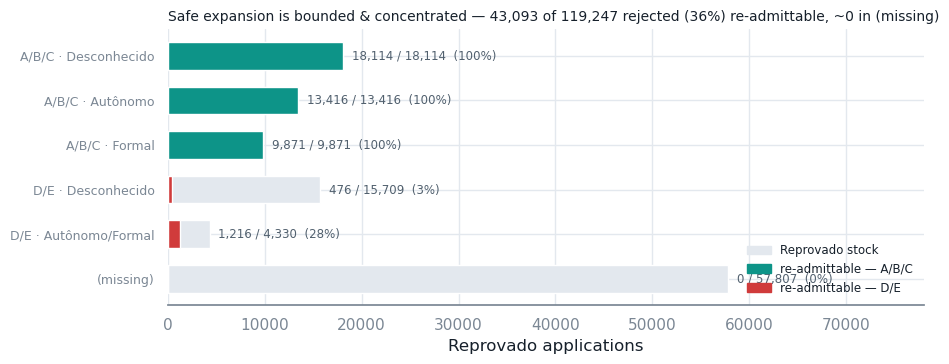

In [8]:
# Deck figure (slide 13) — where the re-admittable Reprovado sits: concentrated in A/B/C,
# top-score slivers of D/E, and *none* of (missing) (kept as the client already decided).
rej = app[app["STATUS"] == "Reprovado"].copy()
rej["admitted"] = pol.approve(rej, policy).values
exp_seg = (rej.groupby("segmento", observed=False)
           .agg(total=("admitted", "size"), admitted=("admitted", "sum"))
           .reindex(SEGS))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ypos = range(len(SEGS))
ax.barh(ypos, exp_seg["total"], color=palette.STOCK_BG, height=0.62)
ax.barh(ypos, exp_seg["admitted"], color=[palette.risk_tier_color(s) for s in SEGS], height=0.62)
for i, s in enumerate(SEGS):
    tot, adm = int(exp_seg.loc[s, "total"]), int(exp_seg.loc[s, "admitted"])
    share = adm / tot if tot else 0
    ax.text(tot + 900, i, f"{adm:,} / {tot:,}  ({share:.0%})", va="center", fontsize=8.5,
            color=palette.INK_2)
ax.set_yticks(ypos, SEGS, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, exp_seg["total"].max() * 1.35)
ax.set_xlabel("Reprovado applications")
n_adm = int(exp_seg["admitted"].sum()); n_tot = int(exp_seg["total"].sum())
ax.set_title(f"Safe expansion is bounded & concentrated — {n_adm:,} of {n_tot:,} rejected "
             f"({n_adm / n_tot:.0%}) re-admittable, ~0 in (missing)", loc="left", fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color=palette.STOCK_BG, label="Reprovado stock"),
    Patch(color=palette.RISK_LOW, label="re-admittable — A/B/C"),
    Patch(color=palette.RISK_HIGH, label="re-admittable — D/E"),
], loc="lower right", frameon=False, fontsize=8.5)
sns.despine(left=True)
plt.tight_layout()
save_fig(fig, "fig_expansion_by_segment.png", FIG_DIR)
plt.show()

**Key takeaway**: for `Reprovado`, the named-segment rules alone would admit **43.1k (36.1% of
119.2k)** at an *assumed* ~7.4% — a real but bounded hypothesis, resting only on evidence we
actually have (segment + score), and safer than the book average (10.3%) precisely because it's
the same cutoffs that clear the current book. `(missing)` contributes **zero** newly-admitted
`Reprovado` (down from 57.8k in the earlier, unflagged design) — those 57.8k stay denied, exactly
as the client already decided. `Aprovado`: 32.6k from named segments (assumed ~7.4%) **+ 37.5k
from `(missing)`, unchanged status quo** (not a new decision, not a hypothesis). Total admitted
stock shrinks from the earlier design's 171k to **113.2k** (43.1k + 32.6k named + 37.5k
`(missing)` status quo) — smaller, but every unit in it is backed by either evidence or the
client's own prior decision, never a guess about a population we can't see.
Recommendation unchanged in kind: adopt the named-segment cutoffs on the current intake, expand
into named-segment `Reprovado` only via a **staged, monitored test**; leave `(missing)` exactly
as the client runs it today unless new data (snapshot/open-finance coverage) closes that gap.

## Key takeaways

- **Frontier built, no cliff**: `(missing)` (49% of book) is a fixed floor — it has no score to
  cut, so `mode: keep_current` defers to the client's own decision instead of a manufactured
  cutoff. The τ-sweep now only trades off the 5 named segments where evidence exists.
- **Operating point (policy_v1.yaml)**: τ* = 11.5% — keep 90% of the book at **9.64% vs 10.30%**;
  removed 10% defaults at 16.3%. A/B/C: no score gate; D/E: score ≥ 595 / ≥ 518, scoreless denied;
  `(missing)`: `keep_current`.
- **Expansion, now properly bounded**: named-segment `Reprovado` admits 36.1% under an explicit,
  evidence-based hypothesis (staged test recommended); `(missing)` `Reprovado` (57.8k) stays
  denied — no hypothesis is asked of the one segment with zero conditioning variables.